# ACSIncome — Illinois (2018)

Exploratory analysis of income outcomes and ACS `SEX` categories, followed by a reproducible train/validation/test split. The outcome is annual personal income above $50,000.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().resolve()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data import load_acs_income
from src.experiment import prepare_data_splits

## Data overview

Load the Illinois ACSIncome sample and inspect the predictors and missing values. `SEX` is kept separately for group-level analysis.

In [2]:
X, y, A = load_acs_income()

print(f"Observations: {len(X):,}; predictors: {X.shape[1]}")
display(X.head())
display(X.isna().sum().rename("Missing values").to_frame())

Observations: 67,016; predictors: 9


,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,RAC1P
0,30.0,1.0,18.0,5.0,4220.0,22.0,17.0,99.0,1.0
1,20.0,1.0,20.0,5.0,7010.0,17.0,17.0,20.0,1.0
2,70.0,1.0,19.0,3.0,4760.0,17.0,16.0,20.0,1.0
3,20.0,1.0,16.0,5.0,4020.0,329.0,16.0,40.0,8.0
4,66.0,3.0,21.0,1.0,2320.0,17.0,16.0,20.0,1.0


,Missing values
AGEP,0
COW,0
SCHL,0
MAR,0
OCCP,0
POBP,0
RELP,0
WKHP,0
RAC1P,0


## Income distribution

The binary target indicates whether annual personal income exceeds $50,000.

,Observations,Share (%)
≤ $50K,NaN,NaN
> $50K,NaN,NaN


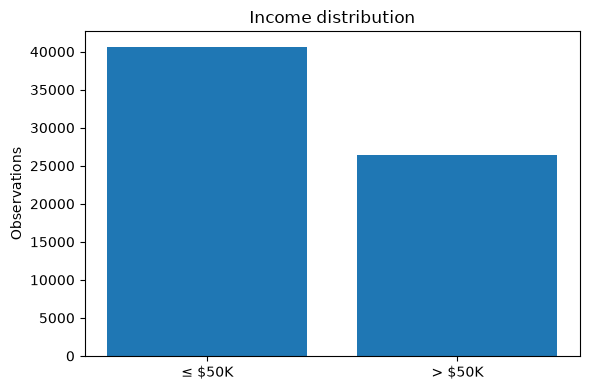

In [3]:
income_counts = y.value_counts().reindex([0, 1], fill_value=0)
income_share = (income_counts / len(y) * 100).round(2)
display(pd.DataFrame({"Observations": income_counts, "Share (%)": income_share},
                     index=["≤ $50K", "> $50K"]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["≤ $50K", "> $50K"], income_counts.values)
ax.set(title="Income distribution", ylabel="Observations")
plt.tight_layout()
plt.show()

## Income by ACS sex category

Compare outcome rates for the two `SEX` categories recorded in ACS (1 = male, 2 = female). These administrative categories do not represent the full range of gender identities. Differences in observed income rates alone do not establish algorithmic bias.

,observations,Income > $50K (%)
SEX,,
Male,34596,47.74
Female,32420,30.40


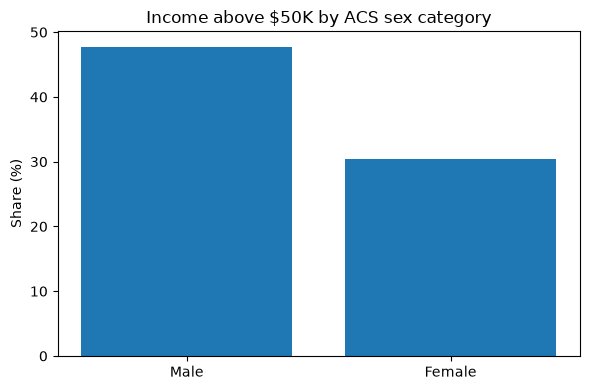

In [4]:
income_by_sex = (
    pd.DataFrame({"SEX": A, "income": y})
    .groupby("SEX")["income"]
    .agg(observations="size", income_rate="mean")
    .rename(index={1: "Male", 2: "Female"})
)
income_by_sex["income_rate"] *= 100
display(income_by_sex.rename(columns={"income_rate": "Income > $50K (%)"}).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(income_by_sex.index, income_by_sex["income_rate"])
ax.set(title="Income above $50K by ACS sex category", ylabel="Share (%)")
plt.tight_layout()
plt.show()

## Age distribution

Inspect the age profile of the sample before model training.

count    67016.000000
mean        43.339979
std         15.092975
min         17.000000
25%         31.000000
50%         43.000000
75%         56.000000
max         94.000000
Name: Age, dtype: float64

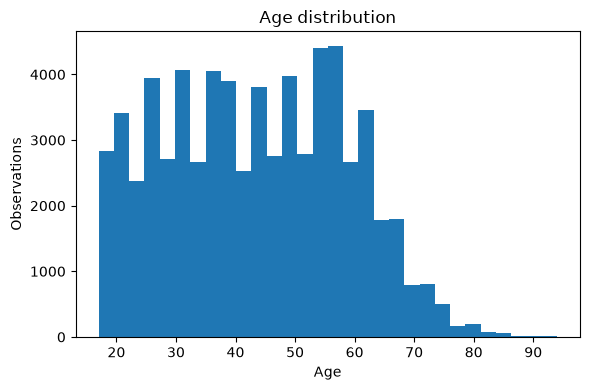

In [5]:
display(X["AGEP"].describe().rename("Age"))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(X["AGEP"], bins=30)
ax.set(title="Age distribution", xlabel="Age", ylabel="Observations")
plt.tight_layout()
plt.show()

## Train, validation, and test sets

Use stratified 60/20/20 splits with a fixed random seed. `SEX` is excluded from model predictors but retained for fairness evaluation; other predictors may still correlate with it.

In [6]:
(
    X_train, X_val, X_test,
    y_train, y_val, y_test,
    A_train, A_val, A_test,
) = prepare_data_splits(X, y, A)

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Observations": len(target),
        "Income > $50K (%)": target.mean() * 100,
        "Male (%)": (group == 1).mean() * 100,
        "Female (%)": (group == 2).mean() * 100,
    }
    for name, target, group in [
        ("Train", y_train, A_train),
        ("Validation", y_val, A_val),
        ("Test", y_test, A_test),
    ]
]).set_index("Split")
display(split_summary.round(2))

,Observations,Income > $50K (%),Male (%),Female (%)
Split,,,,
Train,40209,39.35,51.56,48.44
Validation,13403,39.35,51.75,48.25
Test,13404,39.35,51.69,48.31
